In [1]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import pairwise_distances

warnings.filterwarnings("ignore")

# Project root
PROJECT_ROOT = Path.cwd()

# If your notebook is inside the notebooks folder, move to project root
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODULE5_DIR = PROJECT_ROOT / "data" / "processed" / "module5"
MODULE6_DIR = PROJECT_ROOT / "data" / "processed" / "module6"
VISUAL_DIR = PROJECT_ROOT / "visualizations" / "module6"
REPORT_DIR = PROJECT_ROOT / "reports"

MODULE6_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Module 5 folder:", MODULE5_DIR)
print("Module 6 folder:", MODULE6_DIR)
print("Visualization folder:", VISUAL_DIR)

Project root: c:\Users\nagar\Downloads\routeranker-upload\notebooks
Module 5 folder: c:\Users\nagar\Downloads\routeranker-upload\notebooks\data\processed\module5
Module 6 folder: c:\Users\nagar\Downloads\routeranker-upload\notebooks\data\processed\module6
Visualization folder: c:\Users\nagar\Downloads\routeranker-upload\notebooks\visualizations\module6


In [7]:
from pathlib import Path

# Automatically locate the main project folder
current = Path.cwd()

root = next(
    (folder for folder in [current, *current.parents]
     if (folder / ".git").exists() and (folder / "data").exists()),
    None
)

if root is None:
    raise FileNotFoundError("Project root not found.")

print("PROJECT ROOT:", root)

# Check processed data folders
processed_folder = root / "data" / "processed"

print("\nPROCESSED DATA CONTENTS:")

if processed_folder.exists():
    for item in processed_folder.iterdir():
        print(item.name)
else:
    print("Processed folder not found.")

PROJECT ROOT: c:\Users\nagar\Downloads\routeranker-upload

PROCESSED DATA CONTENTS:
module1
module2
module3
module4
module5


In [8]:
from pathlib import Path

module5_folder = root / "data" / "processed" / "module5"
module4_folder = root / "data" / "processed" / "module4"

print("MODULE 5 FILES")
for file in sorted(module5_folder.rglob("*")):
    if file.is_file():
        print(file.relative_to(root), "|", file.stat().st_size, "bytes")

print("\nMODULE 4 FILES")
for file in sorted(module4_folder.rglob("*")):
    if file.is_file():
        print(file.relative_to(root), "|", file.stat().st_size, "bytes")

MODULE 5 FILES
data\processed\module5\clustering_model_comparison.csv | 66 bytes
data\processed\module5\dbscan_clusters.png | 367465 bytes
data\processed\module5\dbscan_model.joblib | 368815 bytes
data\processed\module5\dbscan_noise_points.csv | 9272 bytes
data\processed\module5\dbscan_parameter_comparison.csv | 436 bytes
data\processed\module5\kmeans_cluster_profile.csv | 255 bytes
data\processed\module5\kmeans_clusters.png | 340793 bytes
data\processed\module5\kmeans_model.joblib | 38479 bytes
data\processed\module5\module5_route_features_with_clusters.csv | 684863 bytes
data\processed\module5\module5_summary.csv | 171 bytes

MODULE 4 FILES
data\processed\module4\duplicate_investigation_report.csv | 393 bytes
data\processed\module4\headway_missing_values_report.csv | 768 bytes
data\processed\module4\headway_quality_report.csv | 229 bytes
data\processed\module4\hyderabad_trip_duration_quality_report.csv | 2305709 bytes
data\processed\module4\iqr_outlier_summary.csv | 376 bytes
data\pr

In [9]:
import json

notebook_path = root / "notebooks" / "Module5_ML_Model_Development.ipynb"

print("Notebook exists:", notebook_path.exists())

if notebook_path.exists():
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook_data = json.load(f)

    keywords = [
        "StandardScaler",
        "MinMaxScaler",
        "fit_transform",
        "selected_features",
        "KMeans(",
        "DBSCAN(",
        "kmeans.fit",
        "dbscan.fit"
    ]

    for i, cell in enumerate(notebook_data["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])

            if any(word in source for word in keywords):
                print(f"\n{'='*60}")
                print("CELL:", i)
                print(source)

Notebook exists: True

CELL: 16
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

CELL: 18
from sklearn.cluster import KMeans

# Select the number of clusters based on your Elbow graph
BEST_K = 3

# Create K-Means model
kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

# Train the model
kmeans_labels = kmeans.fit_predict(X)

# Add cluster labels to the dataset
df['kmeans_cluster'] = kmeans_labels

print("K-Means clustering completed!")
print("\nCluster distribution:")
print(df['kmeans_cluster'].value_counts().sort_index())

CELL: 29
results = []

for eps in [0.3, 0.5, 0.7, 1.0]:
    for min_samples in [5, 10]

In [10]:
for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(term in source.lower() for term in [
            "selected_features",
            "feature_columns",
            "feature_cols",
            "x =",
            "x=",
            "drop("
        ]):
            print(f"\n{'='*60}")
            print("CELL:", i)
            print(source)


CELL: 3
# Select numerical features for clustering

cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Selected features:")
print(cluster_features)

print("\nFeature matrix shape:")
print(X.shape)

print("\nFirst 5 records:")
display(X.head())

print("\nChecking missing values:")
print(X.isnull().sum())

CELL: 9
import pandas as pd

df = pd.read_csv("../data/processed/module4/route_features_scaled.csv")

cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Dataset loaded:", X.shape)

CELL: 15
cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Feature matrix:", X.shape)

CELL: 20
from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X, kmeans_labels)
db_index = davies_bouldin_score(X, kmeans_labels)

print("K

In [11]:
import joblib

module5_folder = root / "data" / "processed" / "module5"

kmeans_path = module5_folder / "kmeans_model.joblib"
dbscan_path = module5_folder / "dbscan_model.joblib"

kmeans_model = joblib.load(kmeans_path)
dbscan_model = joblib.load(dbscan_path)

print("KMeans model loaded:", type(kmeans_model))
print("KMeans cluster centers:")
print(kmeans_model.cluster_centers_)

print("\nDBSCAN model loaded:", type(dbscan_model))
print("DBSCAN eps:", dbscan_model.eps)
print("DBSCAN min_samples:", dbscan_model.min_samples)
print("DBSCAN metric:", dbscan_model.metric)
print("DBSCAN core samples:", len(dbscan_model.components_))

KMeans model loaded: <class 'sklearn.cluster._kmeans.KMeans'>
KMeans cluster centers:
[[-0.10115495  0.63453789  0.81521019]
 [-0.15385074 -0.64866984 -0.74943121]
 [ 4.45819065  0.82834471 -0.43344012]]

DBSCAN model loaded: <class 'sklearn.cluster._dbscan.DBSCAN'>
DBSCAN eps: 0.7
DBSCAN min_samples: 10
DBSCAN metric: euclidean
DBSCAN core samples: 9161


In [12]:
import pandas as pd
from pathlib import Path

# Find the main project folder
current = Path.cwd()

root = next(
    (
        folder for folder in [current, *current.parents]
        if (folder / ".git").exists() and (folder / "data").exists()
    ),
    None
)

if root is None:
    raise FileNotFoundError("Project root not found.")

# Load Module 4 and Module 5 datasets
module4_path = (
    root / "data" / "processed" / "module4" / "route_features_scaled.csv"
)

module5_path = (
    root / "data" / "processed" / "module5" / "module5_route_features_with_clusters.csv"
)

module4_df = pd.read_csv(module4_path)
module5_df = pd.read_csv(module5_path)

print("PROJECT ROOT:")
print(root)

print("\nMODULE 4 DATASET")
print("Shape:", module4_df.shape)
print("Columns:", module4_df.columns.tolist())
print("\nFirst 5 rows:")
display(module4_df.head())

print("\nMODULE 5 DATASET")
print("Shape:", module5_df.shape)
print("Columns:", module5_df.columns.tolist())
print("\nFirst 5 rows:")
display(module5_df.head())

PROJECT ROOT:
c:\Users\nagar\Downloads\routeranker-upload

MODULE 4 DATASET
Shape: (9338, 8)
Columns: ['trip_count', 'distinct_stop_count', 'average_stops_per_trip', 'city_Bangalore', 'city_Delhi', 'city_Hyderabad', 'city_Mumbai', 'city_Pune']

First 5 rows:


,trip_count,distinct_stop_count,average_stops_per_trip,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune
0,-0.397566,-0.210807,-0.618302,1,0,0,0,0
1,-0.397566,-1.216965,-1.579736,1,0,0,0,0
2,-0.383906,-0.122029,-0.571172,1,0,0,0,0
3,-0.370245,-0.122029,-0.561747,1,0,0,0,0
4,-0.383906,-0.299586,-0.759689,1,0,0,0,0



MODULE 5 DATASET
Shape: (9338, 10)
Columns: ['trip_count', 'distinct_stop_count', 'average_stops_per_trip', 'city_Bangalore', 'city_Delhi', 'city_Hyderabad', 'city_Mumbai', 'city_Pune', 'kmeans_cluster', 'dbscan_cluster']

First 5 rows:


,trip_count,distinct_stop_count,average_stops_per_trip,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune,kmeans_cluster,dbscan_cluster
0,-0.397566,-0.210807,-0.618302,1,0,0,0,0,1,0
1,-0.397566,-1.216965,-1.579736,1,0,0,0,0,1,0
2,-0.383906,-0.122029,-0.571172,1,0,0,0,0,1,0
3,-0.370245,-0.122029,-0.561747,1,0,0,0,0,1,0
4,-0.383906,-0.299586,-0.759689,1,0,0,0,0,1,0


In [13]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.neighbors import NearestNeighbors

# --------------------------------------------------
# 1. Load the saved Module 5 models
# --------------------------------------------------

module5_folder = root / "data" / "processed" / "module5"

kmeans_model = joblib.load(module5_folder / "kmeans_model.joblib")
dbscan_model = joblib.load(module5_folder / "dbscan_model.joblib")

# --------------------------------------------------
# 2. Prepare the same three features used in Module 5
# --------------------------------------------------

feature_columns = [
    "trip_count",
    "distinct_stop_count",
    "average_stops_per_trip"
]

X_new = module4_df[feature_columns].copy()

if X_new.isnull().any().any():
    raise ValueError("Missing values found in the model features.")

print("Inference input shape:", X_new.shape)
print("Features:", feature_columns)

# --------------------------------------------------
# 3. KMeans inference
# --------------------------------------------------

kmeans_predictions = kmeans_model.predict(X_new)

# --------------------------------------------------
# 4. DBSCAN neighborhood-based assignment
# DBSCAN does not have a standard predict() method.
# This is an approximate assignment using its core points.
# --------------------------------------------------

core_points = dbscan_model.components_

core_labels = dbscan_model.labels_[
    dbscan_model.core_sample_indices_
]

neighbor_model = NearestNeighbors(
    radius=dbscan_model.eps,
    metric=dbscan_model.metric
)

neighbor_model.fit(core_points)

distances, neighbor_indices = neighbor_model.radius_neighbors(
    X_new,
    return_distance=True
)

dbscan_predictions = []
dbscan_ambiguous = []

for point_distances, point_indices in zip(distances, neighbor_indices):

    if len(point_indices) == 0:
        # No nearby core point
        dbscan_predictions.append(-1)
        dbscan_ambiguous.append(False)

    else:
        nearby_labels = core_labels[point_indices]
        unique_labels = np.unique(nearby_labels)

        if len(unique_labels) == 1:
            dbscan_predictions.append(int(unique_labels[0]))
            dbscan_ambiguous.append(False)

        else:
            # Multiple DBSCAN clusters are nearby.
            # Choose the closest core point and flag ambiguity.
            closest_position = np.argmin(point_distances)
            selected_label = nearby_labels[closest_position]

            dbscan_predictions.append(int(selected_label))
            dbscan_ambiguous.append(True)

# --------------------------------------------------
# 5. Create the inference results
# --------------------------------------------------

inference_df = module4_df.copy()

inference_df["kmeans_inference_cluster"] = kmeans_predictions
inference_df["dbscan_neighborhood_assignment"] = dbscan_predictions
inference_df["dbscan_assignment_ambiguous"] = dbscan_ambiguous

# Compare against the labels saved in Module 5
inference_df["kmeans_original_cluster"] = module5_df["kmeans_cluster"]
inference_df["dbscan_original_cluster"] = module5_df["dbscan_cluster"]

# Add a readable city label
city_columns = [
    "city_Bangalore",
    "city_Delhi",
    "city_Hyderabad",
    "city_Mumbai",
    "city_Pune"
]

inference_df["city"] = (
    module4_df[city_columns]
    .idxmax(axis=1)
    .str.replace("city_", "", regex=False)
)

# --------------------------------------------------
# 6. Save the inference results
# --------------------------------------------------

module6_folder = root / "data" / "processed" / "module6"
module6_folder.mkdir(parents=True, exist_ok=True)

inference_path = module6_folder / "module6_inference_results.csv"
inference_df.to_csv(inference_path, index=False)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("\nKMEANS INFERENCE")
print("Cluster distribution:")
print(inference_df["kmeans_inference_cluster"].value_counts().sort_index())

kmeans_match = (
    inference_df["kmeans_inference_cluster"]
    == inference_df["kmeans_original_cluster"]
).mean()

print("\nKMeans agreement with saved labels:", round(kmeans_match * 100, 2), "%")

print("\nDBSCAN NEIGHBORHOOD ASSIGNMENT")
print("Assignment distribution:")
print(
    inference_df["dbscan_neighborhood_assignment"]
    .value_counts()
    .sort_index()
)

print(
    "\nAmbiguous DBSCAN assignments:",
    int(inference_df["dbscan_assignment_ambiguous"].sum())
)

dbscan_match = (
    inference_df["dbscan_neighborhood_assignment"]
    == inference_df["dbscan_original_cluster"]
).mean()

print(
    "DBSCAN agreement with saved labels:",
    round(dbscan_match * 100, 2),
    "%"
)

print("\nSaved inference file:")
print(inference_path)

print("\nFirst 5 inference records:")
display(inference_df.head())

Inference input shape: (9338, 3)
Features: ['trip_count', 'distinct_stop_count', 'average_stops_per_trip']

KMEANS INFERENCE
Cluster distribution:
kmeans_inference_cluster
0    4420
1    4657
2     261
Name: count, dtype: int64

KMeans agreement with saved labels: 100.0 %

DBSCAN NEIGHBORHOOD ASSIGNMENT
Assignment distribution:
dbscan_neighborhood_assignment
-1     126
 0    9182
 1      30
Name: count, dtype: int64

Ambiguous DBSCAN assignments: 2
DBSCAN agreement with saved labels: 100.0 %

Saved inference file:
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\module6_inference_results.csv

First 5 inference records:


,trip_count,distinct_stop_count,average_stops_per_trip,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune,kmeans_inference_cluster,dbscan_neighborhood_assignment,dbscan_assignment_ambiguous,kmeans_original_cluster,dbscan_original_cluster,city
0,-0.397566,-0.210807,-0.618302,1,0,0,0,0,1,0,False,1,0,Bangalore
1,-0.397566,-1.216965,-1.579736,1,0,0,0,0,1,0,False,1,0,Bangalore
2,-0.383906,-0.122029,-0.571172,1,0,0,0,0,1,0,False,1,0,Bangalore
3,-0.370245,-0.122029,-0.561747,1,0,0,0,0,1,0,False,1,0,Bangalore
4,-0.383906,-0.299586,-0.759689,1,0,0,0,0,1,0,False,1,0,Bangalore


In [14]:
# --------------------------------------------------
# 1. Identify unusual DBSCAN records
# --------------------------------------------------

noise_records = inference_df[
    inference_df["dbscan_neighborhood_assignment"] == -1
].copy()

ambiguous_records = inference_df[
    inference_df["dbscan_assignment_ambiguous"] == True
].copy()

print("DBSCAN NOISE ANALYSIS")
print("Total noise records:", len(noise_records))

print("\nNoise records by city:")
print(noise_records["city"].value_counts())

print("\nAMBIGUOUS RECORD ANALYSIS")
print("Total ambiguous records:", len(ambiguous_records))

print("\nAmbiguous records by city:")
print(ambiguous_records["city"].value_counts())

# --------------------------------------------------
# 2. KMeans cluster distribution by city
# --------------------------------------------------

cluster_city_summary = pd.crosstab(
    inference_df["city"],
    inference_df["kmeans_inference_cluster"]
)

print("\nKMEANS CLUSTER DISTRIBUTION BY CITY")
display(cluster_city_summary)

# --------------------------------------------------
# 3. Calculate feature averages by KMeans cluster
# --------------------------------------------------

cluster_profiles = inference_df.groupby(
    "kmeans_inference_cluster"
)[feature_columns].mean().round(3)

print("\nKMEANS CLUSTER FEATURE PROFILES")
display(cluster_profiles)

# --------------------------------------------------
# 4. Save analysis outputs
# --------------------------------------------------

noise_path = module6_folder / "module6_dbscan_noise_records.csv"
ambiguous_path = module6_folder / "module6_dbscan_ambiguous_records.csv"
city_summary_path = module6_folder / "module6_cluster_city_summary.csv"
profile_path = module6_folder / "module6_kmeans_cluster_profiles.csv"

noise_records.to_csv(noise_path, index=False)
ambiguous_records.to_csv(ambiguous_path, index=False)
cluster_city_summary.to_csv(city_summary_path)
cluster_profiles.to_csv(profile_path)

print("\nSaved analysis files:")
print(noise_path)
print(ambiguous_path)
print(city_summary_path)
print(profile_path)

DBSCAN NOISE ANALYSIS
Total noise records: 126

Noise records by city:
city
Hyderabad    83
Mumbai       35
Pune          4
Bangalore     2
Delhi         2
Name: count, dtype: int64

AMBIGUOUS RECORD ANALYSIS
Total ambiguous records: 2

Ambiguous records by city:
city
Mumbai    2
Name: count, dtype: int64

KMEANS CLUSTER DISTRIBUTION BY CITY


kmeans_inference_cluster,0,1,2
city,,,
Bangalore,1895,2490,31
Delhi,1702,1262,0
Hyderabad,410,558,63
Mumbai,190,255,167
Pune,223,92,0



KMEANS CLUSTER FEATURE PROFILES


,trip_count,distinct_stop_count,average_stops_per_trip
kmeans_inference_cluster,,,
0,-0.101,0.635,0.815
1,-0.154,-0.649,-0.749
2,4.458,0.828,-0.433



Saved analysis files:
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\module6_dbscan_noise_records.csv
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\module6_dbscan_ambiguous_records.csv
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\module6_cluster_city_summary.csv
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\module6_kmeans_cluster_profiles.csv


CITY-WISE DBSCAN NOISE SUMMARY


,total_records,noise_records,noise_percentage
city,,,
Hyderabad,1031,83,8.05
Mumbai,612,35,5.72
Pune,315,4,1.27
Delhi,2964,2,0.07
Bangalore,4416,2,0.05


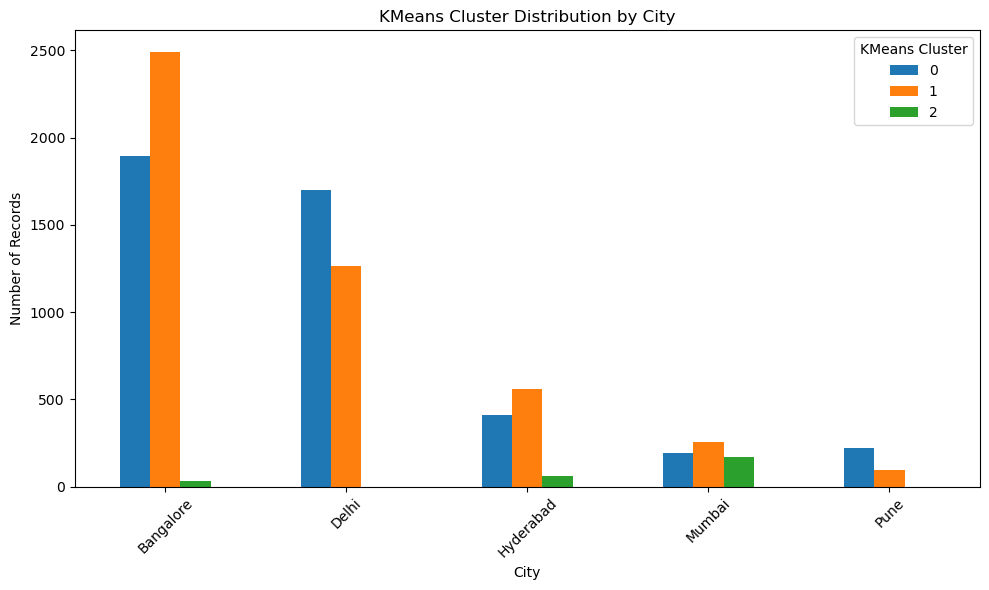

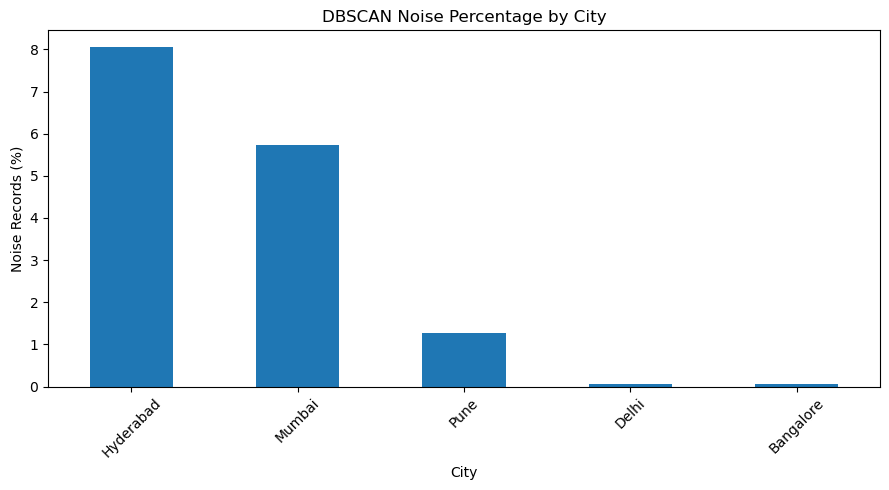

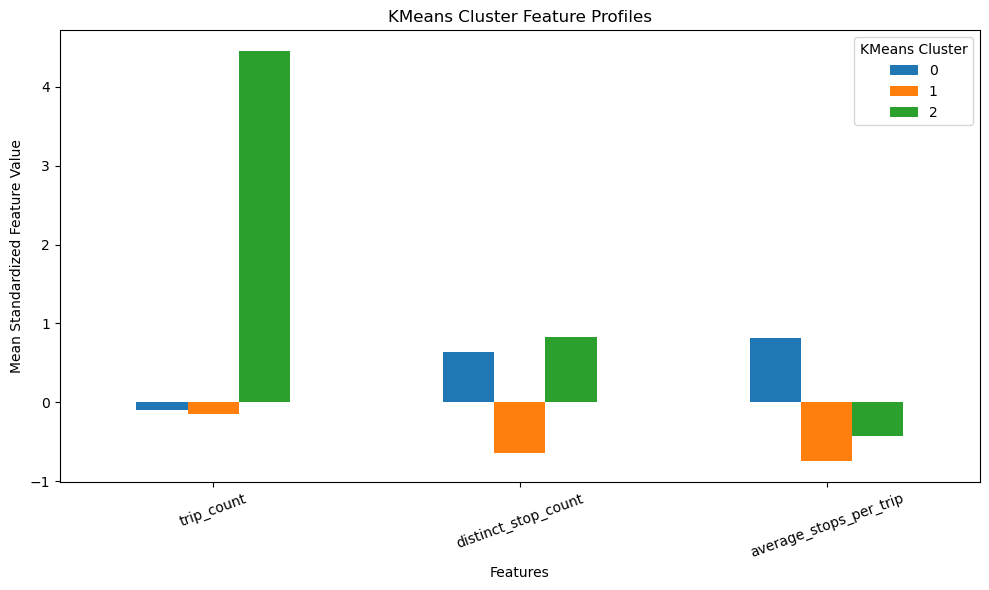


All three charts and the city noise summary have been saved.


In [15]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Calculate total records and DBSCAN noise rate by city
# --------------------------------------------------

city_total = inference_df.groupby("city").size()

city_noise = noise_records.groupby("city").size()

city_noise_summary = pd.DataFrame({
    "total_records": city_total,
    "noise_records": city_noise
}).fillna(0)

city_noise_summary["noise_records"] = (
    city_noise_summary["noise_records"].astype(int)
)

city_noise_summary["noise_percentage"] = (
    city_noise_summary["noise_records"]
    / city_noise_summary["total_records"] * 100
).round(2)

city_noise_summary = city_noise_summary.sort_values(
    "noise_percentage", ascending=False
)

print("CITY-WISE DBSCAN NOISE SUMMARY")
display(city_noise_summary)

# Save summary
city_noise_summary.to_csv(
    module6_folder / "module6_city_noise_summary.csv"
)

# --------------------------------------------------
# 2. Chart: KMeans cluster distribution by city
# --------------------------------------------------

cluster_city_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KMeans Cluster Distribution by City")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.legend(title="KMeans Cluster")
plt.tight_layout()

plt.savefig(
    module6_folder / "module6_kmeans_city_distribution.png",
    dpi=300
)

plt.show()

# --------------------------------------------------
# 3. Chart: DBSCAN noise percentage by city
# --------------------------------------------------

city_noise_summary["noise_percentage"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("DBSCAN Noise Percentage by City")
plt.xlabel("City")
plt.ylabel("Noise Records (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    module6_folder / "module6_dbscan_noise_percentage.png",
    dpi=300
)

plt.show()

# --------------------------------------------------
# 4. Chart: KMeans cluster feature profiles
# --------------------------------------------------

cluster_profiles.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KMeans Cluster Feature Profiles")
plt.xlabel("Features")
plt.ylabel("Mean Standardized Feature Value")
plt.xticks(rotation=20)
plt.legend(title="KMeans Cluster")
plt.tight_layout()

plt.savefig(
    module6_folder / "module6_kmeans_cluster_profiles.png",
    dpi=300
)

plt.show()

print("\nAll three charts and the city noise summary have been saved.")

In [16]:
from pathlib import Path
import pandas as pd

processed_folder = root / "data" / "processed"

print("SEARCHING PROCESSED DATASETS FOR ROUTE-LEVEL INFORMATION\n")

for csv_path in sorted(processed_folder.rglob("*.csv")):

    try:
        sample_df = pd.read_csv(csv_path, nrows=3)

        columns = sample_df.columns.tolist()

        relevant_terms = [
            "route_id", "route_name", "trip_id",
            "stop_id", "distance", "length",
            "shape", "city", "trip_count",
            "stop_count", "route"
        ]

        relevant_columns = [
            col for col in columns
            if any(term in col.lower() for term in relevant_terms)
        ]

        if relevant_columns:
            print("-" * 65)
            print("FILE:", csv_path.relative_to(root))
            print("COLUMNS:", columns)
            print("POTENTIALLY USEFUL:", relevant_columns)

    except Exception as error:
        print("Could not inspect:", csv_path.name, "|", error)

print("\nDATASET SEARCH COMPLETED.")

SEARCHING PROCESSED DATASETS FOR ROUTE-LEVEL INFORMATION

-----------------------------------------------------------------
FILE: data\processed\module1\all_cities_gtfs_column_verification.csv
COLUMNS: ['City', 'File', 'Status', 'Missing Columns']
POTENTIALLY USEFUL: ['City']
-----------------------------------------------------------------
FILE: data\processed\module1\all_cities_gtfs_loading_summary.csv
COLUMNS: ['City', 'File', 'Status', 'Records']
POTENTIALLY USEFUL: ['City']
-----------------------------------------------------------------
FILE: data\processed\module1\all_cities_gtfs_relationship_verification.csv
COLUMNS: ['City', 'Relationship', 'Status']
POTENTIALLY USEFUL: ['City']
-----------------------------------------------------------------
FILE: data\processed\module1\module1_data_quality_check.csv
COLUMNS: ['City', 'File', 'Status', 'Records']
POTENTIALLY USEFUL: ['City']
-----------------------------------------------------------------
FILE: data\processed\module1\modul

In [17]:
# Load Module 2 route-level datasets
module2_folder = root / "data" / "processed" / "module2"

route_profile_path = module2_folder / "all_cities_route_profile.csv"
hourly_path = module2_folder / "all_cities_route_hourly_counts.csv"

route_profile_df = pd.read_csv(route_profile_path)
route_hourly_df = pd.read_csv(hourly_path)

print("ROUTE PROFILE DATASET")
print("Shape:", route_profile_df.shape)
print("Columns:", route_profile_df.columns.tolist())
display(route_profile_df.head())

print("\nROUTE HOURLY COUNTS DATASET")
print("Shape:", route_hourly_df.shape)
print("Columns:", route_hourly_df.columns.tolist())
display(route_hourly_df.head())

# Check route ID availability and duplicates
print("\nROUTE PROFILE CHECKS")
print("Missing route IDs:", route_profile_df["route_id"].isna().sum())
print("Duplicate city-route combinations:",
      route_profile_df.duplicated(["city", "route_id"]).sum())

print("\nROUTE COUNTS BY CITY")
print(route_profile_df.groupby("city")["route_id"].nunique())

print("\nSCHEDULED TRIPS SUMMARY")
display(
    route_profile_df.groupby("city")["trip_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

ROUTE PROFILE DATASET
Shape: (9679, 10)
Columns: ['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city']


,route_long_name,route_short_name,agency_id,route_type,route_id,trip_count,service_count,distinct_stop_count,average_stops_per_trip,city
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447,2.0,1.0,41.0,21.500000,Bangalore
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041,2.0,1.0,7.0,4.500000,Bangalore
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712,3.0,1.0,44.0,22.333333,Bangalore
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821,4.0,1.0,44.0,22.500000,Bangalore
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809,3.0,1.0,38.0,19.000000,Bangalore



ROUTE HOURLY COUNTS DATASET
Shape: (73039, 4)
Columns: ['city', 'route_id', 'hour', 'trip_count']


,city,route_id,hour,trip_count
0,Bangalore,991,5,6
1,Bangalore,991,6,10
2,Bangalore,991,7,14
3,Bangalore,991,8,13
4,Bangalore,991,9,12



ROUTE PROFILE CHECKS
Missing route IDs: 0
Duplicate city-route combinations: 0

ROUTE COUNTS BY CITY
city
Bangalore    4434
Delhi        2964
Hyderabad    1031
Mumbai        935
Pune          315
Name: route_id, dtype: int64

SCHEDULED TRIPS SUMMARY


,count,mean,median,min,max
city,,,,,
Bangalore,4416,13.10,3.0,1.0,398.0
Delhi,2964,26.49,18.0,1.0,170.0
Hyderabad,1031,43.54,8.0,1.0,2087.0
Mumbai,612,161.90,116.0,1.0,930.0
Pune,315,32.15,22.0,3.0,175.0


In [20]:
import pandas as pd

# Exact Module 2 dataset paths
route_profile_path = (
    root / "data" / "processed" / "module2"
    / "all_cities_route_profile.csv"
)

hourly_path = (
    root / "data" / "processed" / "module2"
    / "all_cities_route_hourly_counts.csv"
)

# Check files exist
if not route_profile_path.exists():
    raise FileNotFoundError(route_profile_path)

if not hourly_path.exists():
    raise FileNotFoundError(hourly_path)

# Load datasets
route_profile_df = pd.read_csv(route_profile_path)
hourly_df = pd.read_csv(hourly_path)

print("ROUTE PROFILE SHAPE:", route_profile_df.shape)
print("HOURLY DATA SHAPE:", hourly_df.shape)

# Validate required columns
print("\nRoute profile columns:")
print(route_profile_df.columns.tolist())

print("\nHourly data columns:")
print(hourly_df.columns.tolist())

# Standardize IDs for comparison
route_profile_df["route_key"] = (
    route_profile_df["route_id"].astype(str)
)

hourly_df["route_key"] = (
    hourly_df["route_id"].astype(str)
)

# Calculate hourly trip totals for each route
hourly_route_totals = (
    hourly_df.groupby(["city", "route_key"])["trip_count"]
    .sum()
    .reset_index(name="hourly_total_trips")
)

profile_totals = route_profile_df[
    ["city", "route_key", "trip_count"]
].rename(
    columns={"trip_count": "profile_total_trips"}
)

# Compare route-level trip totals
reconciliation = profile_totals.merge(
    hourly_route_totals,
    on=["city", "route_key"],
    how="outer",
    indicator=True
)

reconciliation["trip_difference"] = (
    reconciliation["hourly_total_trips"]
    - reconciliation["profile_total_trips"]
)

print("\nROUTE MATCHING SUMMARY")
print(reconciliation["_merge"].value_counts())

matched = reconciliation[
    reconciliation["_merge"] == "both"
]

print("\nMATCHED ROUTES:", len(matched))

print(
    "Matching trip totals:",
    int((matched["trip_difference"] == 0).sum())
)

print(
    "Different trip totals:",
    int((matched["trip_difference"] != 0).sum())
)

print("\nFIRST 10 DIFFERENCES:")
display(
    matched.loc[
        matched["trip_difference"] != 0
    ].head(10)
)

ROUTE PROFILE SHAPE: (9679, 10)
HOURLY DATA SHAPE: (73039, 4)

Route profile columns:
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city']

Hourly data columns:
['city', 'route_id', 'hour', 'trip_count']

ROUTE MATCHING SUMMARY
_merge
both          9338
left_only      341
right_only       0
Name: count, dtype: int64

MATCHED ROUTES: 9338
Matching trip totals: 9338
Different trip totals: 0

FIRST 10 DIFFERENCES:


,city,route_key,profile_total_trips,hourly_total_trips,_merge,trip_difference


In [23]:
# Reset indexes for both datasets
route_city = route_profile_df["city"].reset_index(drop=True)
inference_city = inference_df["city"].reset_index(drop=True)

print("Route profile rows:", len(route_city))
print("Inference rows:", len(inference_city))

if len(route_city) != len(inference_city):
    print("\nWARNING: Row counts are different.")
else:
    matches = route_city.eq(inference_city)

    print("\nMatching city labels:", int(matches.sum()))
    print("Non-matching city labels:", int((~matches).sum()))
    print("All city labels match:", bool(matches.all()))

    print("\nRoute profile city counts:")
    print(route_city.value_counts().sort_index())

    print("\nInference city counts:")
    print(inference_city.value_counts().sort_index())

    if not matches.all():
        print("\nFirst mismatched rows:")
        display(pd.DataFrame({
            "route_city": route_city,
            "inference_city": inference_city
        }).loc[~matches].head(10))

Route profile rows: 9679
Inference rows: 9338



In [24]:
# Check missing values in the route profile features
feature_columns = [
    "trip_count",
    "distinct_stop_count",
    "average_stops_per_trip"
]

print("Missing values in route profile:")
print(route_profile_df[feature_columns].isna().sum())

# Keep only records with all three required model features
eligible_routes_df = route_profile_df.dropna(
    subset=feature_columns
).copy()

print("\nTotal route profile records:", len(route_profile_df))
print("Eligible route records:", len(eligible_routes_df))
print("Excluded route records:", len(route_profile_df) - len(eligible_routes_df))

print("\nEligible routes by city:")
print(eligible_routes_df["city"].value_counts().sort_index())

print("\nExcluded routes by city:")
print(
    route_profile_df.loc[
        ~route_profile_df.index.isin(eligible_routes_df.index),
        "city"
    ].value_counts().sort_index()
)

Missing values in route profile:
trip_count                341
distinct_stop_count       341
average_stops_per_trip    341
dtype: int64

Total route profile records: 9679
Eligible route records: 9338
Excluded route records: 341

Eligible routes by city:
city
Bangalore    4416
Delhi        2964
Hyderabad    1031
Mumbai        612
Pune          315
Name: count, dtype: int64

Excluded routes by city:
city
Bangalore     18
Mumbai       323
Name: count, dtype: int64


In [25]:
# Reset indexes to compare records safely
eligible_routes_df = eligible_routes_df.reset_index(drop=True)
module4_check = module4_df.reset_index(drop=True)

print("Eligible route rows:", len(eligible_routes_df))
print("Module 4 rows:", len(module4_check))

# Check whether city labels match row by row
city_match = (
    eligible_routes_df["city"].reset_index(drop=True)
    .eq(inference_df["city"].reset_index(drop=True))
)

print("\nCity labels match:", bool(city_match.all()))
print("Matching city rows:", int(city_match.sum()))

# Check the original raw features against the Module 4 standardized features
print("\nFirst five eligible route records:")
display(eligible_routes_df[["city"] + feature_columns].head())

print("\nFirst five Module 4 feature records:")
display(module4_check[["city_Bangalore", "city_Delhi",
                       "city_Hyderabad", "city_Mumbai",
                       "city_Pune"] + feature_columns].head())

Eligible route rows: 9338
Module 4 rows: 9338

City labels match: True
Matching city rows: 9338

First five eligible route records:


,city,trip_count,distinct_stop_count,average_stops_per_trip
0,Bangalore,2.0,41.0,21.500000
1,Bangalore,2.0,7.0,4.500000
2,Bangalore,3.0,44.0,22.333333
3,Bangalore,4.0,44.0,22.500000
4,Bangalore,3.0,38.0,19.000000



First five Module 4 feature records:


,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune,trip_count,distinct_stop_count,average_stops_per_trip
0,1,0,0,0,0,-0.397566,-0.210807,-0.618302
1,1,0,0,0,0,-0.397566,-1.216965,-1.579736
2,1,0,0,0,0,-0.383906,-0.122029,-0.571172
3,1,0,0,0,0,-0.370245,-0.122029,-0.561747
4,1,0,0,0,0,-0.383906,-0.299586,-0.759689


In [26]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Reproduce standardization only for validation
validation_scaler = StandardScaler()

recalculated_features = validation_scaler.fit_transform(
    eligible_routes_df[feature_columns]
)

saved_features = module4_check[feature_columns].to_numpy()

# Compare recalculated values with saved Module 4 values
differences = np.abs(recalculated_features - saved_features)

print("Maximum numeric difference:", differences.max())
print("Mean numeric difference:", differences.mean())

numeric_match = np.allclose(
    recalculated_features,
    saved_features,
    atol=1e-6
)

print("\nNumeric features match:", numeric_match)

# Check route identifiers
print("\nMissing route IDs:", eligible_routes_df["route_id"].isna().sum())
print("Duplicate city-route combinations:",
      eligible_routes_df.duplicated(["city", "route_id"]).sum())

Maximum numeric difference: 1.7763568394002505e-15
Mean numeric difference: 2.2320446207027238e-17

Numeric features match: True

Missing route IDs: 0
Duplicate city-route combinations: 0


In [27]:
# Start with the 9,338 eligible route records
optimization_df = eligible_routes_df.copy().reset_index(drop=True)

# Attach Module 6 inference results
optimization_df["kmeans_cluster"] = (
    inference_df["kmeans_inference_cluster"].reset_index(drop=True)
)

optimization_df["dbscan_cluster"] = (
    inference_df["dbscan_neighborhood_assignment"].reset_index(drop=True)
)

optimization_df["dbscan_assignment_ambiguous"] = (
    inference_df["dbscan_assignment_ambiguous"].reset_index(drop=True)
)

# Add route review indicators
optimization_df["low_trip_count_candidate"] = (
    optimization_df.groupby("city")["trip_count"]
    .transform(lambda x: x <= x.quantile(0.10))
)

optimization_df["high_trip_count_candidate"] = (
    optimization_df.groupby("city")["trip_count"]
    .transform(lambda x: x >= x.quantile(0.90))
)

optimization_df["dbscan_noise_candidate"] = (
    optimization_df["dbscan_cluster"] == -1
)

# Display results
print("Optimization dataset shape:", optimization_df.shape)

print("\nColumns:")
print(optimization_df.columns.tolist())

print("\nCandidate summary:")
print(
    optimization_df[
        [
            "low_trip_count_candidate",
            "high_trip_count_candidate",
            "dbscan_noise_candidate",
            "dbscan_assignment_ambiguous"
        ]
    ].sum()
)

print("\nSample route records:")
display(
    optimization_df[
        [
            "city",
            "route_id",
            "trip_count",
            "kmeans_cluster",
            "dbscan_cluster",
            "low_trip_count_candidate",
            "high_trip_count_candidate",
            "dbscan_noise_candidate"
        ]
    ].head(10)
)

Optimization dataset shape: (9338, 17)

Columns:
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city', 'route_key', 'kmeans_cluster', 'dbscan_cluster', 'dbscan_assignment_ambiguous', 'low_trip_count_candidate', 'high_trip_count_candidate', 'dbscan_noise_candidate']

Candidate summary:
low_trip_count_candidate       1711
high_trip_count_candidate       939
dbscan_noise_candidate          126
dbscan_assignment_ambiguous       2
dtype: int64

Sample route records:


,city,route_id,trip_count,kmeans_cluster,dbscan_cluster,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
0,Bangalore,3447,2.0,1,0,False,False,False
1,Bangalore,7041,2.0,1,0,False,False,False
2,Bangalore,2712,3.0,1,0,False,False,False
3,Bangalore,4821,4.0,1,0,False,False,False
4,Bangalore,2809,3.0,1,0,False,False,False
5,Bangalore,4673,6.0,1,0,False,False,False
6,Bangalore,4681,5.0,1,0,False,False,False
7,Bangalore,8574,12.0,0,0,False,False,False
8,Bangalore,7674,1.0,1,0,True,False,False
9,Bangalore,5985,2.0,1,0,False,False,False


In [28]:
# Prepare route-level clustering information
route_cluster_info = optimization_df[
    [
        "city",
        "route_id",
        "kmeans_cluster",
        "dbscan_cluster",
        "low_trip_count_candidate",
        "high_trip_count_candidate"
    ]
].copy()

# Ensure route IDs use the same data type
route_cluster_info["route_id"] = (
    route_cluster_info["route_id"].astype(str)
)

hourly_simulation_df = hourly_df.copy()

hourly_simulation_df["route_id"] = (
    hourly_simulation_df["route_id"].astype(str)
)

# Attach route-level information to hourly records
hourly_simulation_df = hourly_simulation_df.merge(
    route_cluster_info,
    on=["city", "route_id"],
    how="inner",
    validate="many_to_one"
)

print("Original hourly records:", len(hourly_df))
print("Matched hourly records:", len(hourly_simulation_df))

print("\nHourly records by city:")
print(hourly_simulation_df.groupby("city").size())

print("\nSample hourly records:")
display(hourly_simulation_df.head(10))

Original hourly records: 73039
Matched hourly records: 73039

Hourly records by city:
city
Bangalore    21805
Delhi        29486
Hyderabad     8262
Mumbai       10575
Pune          2911
dtype: int64

Sample hourly records:


,city,route_id,hour,trip_count,route_key,kmeans_cluster,dbscan_cluster,low_trip_count_candidate,high_trip_count_candidate
0,Bangalore,991,5,6,991,1,0,False,True
1,Bangalore,991,6,10,991,1,0,False,True
2,Bangalore,991,7,14,991,1,0,False,True
3,Bangalore,991,8,13,991,1,0,False,True
4,Bangalore,991,9,12,991,1,0,False,True
5,Bangalore,991,10,11,991,1,0,False,True
6,Bangalore,991,11,18,991,1,0,False,True
7,Bangalore,991,12,16,991,1,0,False,True
8,Bangalore,991,13,9,991,1,0,False,True
9,Bangalore,991,14,13,991,1,0,False,True


In [29]:
import numpy as np
import pandas as pd

# Make a separate copy; never overwrite original hourly data
simulated_hourly_df = hourly_simulation_df.copy()

# Preserve original scheduled trips
simulated_hourly_df["original_trip_count"] = (
    simulated_hourly_df["trip_count"]
)

# Apply illustrative 10% increase only to low-trip candidates
increase_mask = simulated_hourly_df["low_trip_count_candidate"]

simulated_hourly_df["simulated_trip_count"] = np.where(
    increase_mask,
    simulated_hourly_df["trip_count"] * 1.10,
    simulated_hourly_df["trip_count"]
)

# Calculate overall comparison
original_total = simulated_hourly_df["original_trip_count"].sum()
simulated_total = simulated_hourly_df["simulated_trip_count"].sum()

comparison = pd.DataFrame({
    "metric": [
        "Number of routes",
        "Hourly records",
        "Original scheduled trips",
        "Simulated scheduled trips",
        "Additional simulated trips"
    ],
    "original": [
        simulated_hourly_df["route_id"].nunique(),
        len(simulated_hourly_df),
        original_total,
        original_total,
        0
    ],
    "simulated": [
        simulated_hourly_df["route_id"].nunique(),
        len(simulated_hourly_df),
        original_total,
        simulated_total,
        simulated_total - original_total
    ]
})

print("SIMULATION ASSUMPTION: 10% increase for low-trip candidates")
print("Routes receiving the simulated increase:",
      simulated_hourly_df.loc[increase_mask, "route_id"].nunique())

print("\nOVERALL COMPARISON:")
display(comparison)

print("\nPercentage increase in scheduled trips:",
      round((simulated_total - original_total) / original_total * 100, 2),
      "%")

# Save simulation separately
output_dir = root / "data" / "processed" / "module6"
output_dir.mkdir(parents=True, exist_ok=True)

simulated_hourly_df.to_csv(
    output_dir / "module6_simulated_hourly_schedule.csv",
    index=False
)

comparison.to_csv(
    output_dir / "module6_optimization_comparison.csv",
    index=False
)

print("\nSimulation files saved successfully.")

SIMULATION ASSUMPTION: 10% increase for low-trip candidates
Routes receiving the simulated increase: 1675

OVERALL COMPARISON:


,metric,original,simulated
0,Number of routes,7825,7825.0
1,Hourly records,73039,73039.0
2,Original scheduled trips,290443,290443.0
3,Simulated scheduled trips,290443,290734.8
4,Additional simulated trips,0,291.8



Percentage increase in scheduled trips: 0.1 %

Simulation files saved successfully.


In [30]:
import numpy as np
import pandas as pd

# Work on a separate copy
simulated_hourly_df = hourly_simulation_df.copy().reset_index(drop=True)

# Preserve original integer trip counts
simulated_hourly_df["original_trip_count"] = (
    simulated_hourly_df["trip_count"].astype(int)
)

# Initialize additional trips
simulated_hourly_df["additional_trips"] = 0

# Process each route separately using city + route_id
for (city, route_id), group in simulated_hourly_df.groupby(
    ["city", "route_id"], sort=False
):
    if not bool(group["low_trip_count_candidate"].iloc[0]):
        continue

    original_counts = group["original_trip_count"].to_numpy()
    total_trips = int(original_counts.sum())

    if total_trips == 0:
        continue

    # Increase route's total scheduled trips by 10%, rounded up
    extra_trips = int(np.ceil(total_trips * 0.10))

    # Distribute additional trips proportionally across its hours
    exact_shares = original_counts / total_trips * extra_trips
    additions = np.floor(exact_shares).astype(int)

    remaining = extra_trips - additions.sum()

    if remaining > 0:
        fractional_parts = exact_shares - additions
        selected = np.argsort(-fractional_parts)[:remaining]
        additions[selected] += 1

    simulated_hourly_df.loc[
        group.index, "additional_trips"
    ] = additions

# Calculate simulated hourly counts
simulated_hourly_df["simulated_trip_count"] = (
    simulated_hourly_df["original_trip_count"]
    + simulated_hourly_df["additional_trips"]
)

# Count unique city-route combinations, not route_id alone
original_routes = (
    simulated_hourly_df[["city", "route_id"]]
    .drop_duplicates()
    .shape[0]
)

candidate_routes = (
    simulated_hourly_df.loc[
        simulated_hourly_df["low_trip_count_candidate"],
        ["city", "route_id"]
    ]
    .drop_duplicates()
    .shape[0]
)

original_total = int(
    simulated_hourly_df["original_trip_count"].sum()
)

simulated_total = int(
    simulated_hourly_df["simulated_trip_count"].sum()
)

# Create comparison table
comparison = pd.DataFrame({
    "metric": [
        "Unique city-route combinations",
        "Hourly records",
        "Routes receiving simulated increase",
        "Original scheduled trips",
        "Simulated scheduled trips",
        "Additional simulated trips"
    ],
    "original": [
        original_routes,
        len(simulated_hourly_df),
        0,
        original_total,
        original_total,
        0
    ],
    "simulated": [
        original_routes,
        len(simulated_hourly_df),
        candidate_routes,
        original_total,
        simulated_total,
        simulated_total - original_total
    ]
})

print("CORRECTED INTEGER-BASED SIMULATION")
display(comparison)

print(
    "\nPercentage increase:",
    round((simulated_total - original_total) / original_total * 100, 2),
    "%"
)

print(
    "\nAll simulated trip counts are integers:",
    bool(
        (simulated_hourly_df["simulated_trip_count"] % 1 == 0).all()
    )
)

# Save corrected outputs
output_dir = root / "data" / "processed" / "module6"

simulated_hourly_df.to_csv(
    output_dir / "module6_simulated_hourly_schedule.csv",
    index=False
)

comparison.to_csv(
    output_dir / "module6_optimization_comparison.csv",
    index=False
)

print("\nCorrected simulation files saved.")

CORRECTED INTEGER-BASED SIMULATION


,metric,original,simulated
0,Unique city-route combinations,9338,9338
1,Hourly records,73039,73039
2,Routes receiving simulated increase,0,1711
3,Original scheduled trips,290443,290443
4,Simulated scheduled trips,290443,292174
5,Additional simulated trips,0,1731



Percentage increase: 0.6 %

All simulated trip counts are integers: True

Corrected simulation files saved.


In [31]:
# Calculate city-wise original and simulated trips
city_comparison = (
    simulated_hourly_df
    .groupby("city")
    .agg(
        route_count=("route_id", "nunique"),
        original_trips=("original_trip_count", "sum"),
        simulated_trips=("simulated_trip_count", "sum"),
        additional_trips=("additional_trips", "sum")
    )
    .reset_index()
)

# Correct route count using unique city-route combinations
city_route_counts = (
    simulated_hourly_df[["city", "route_id"]]
    .drop_duplicates()
    .groupby("city")
    .size()
)

city_comparison["route_count"] = (
    city_comparison["city"].map(city_route_counts)
)

city_comparison["percentage_increase"] = (
    city_comparison["additional_trips"]
    / city_comparison["original_trips"] * 100
).round(2)

print("CITY-WISE ORIGINAL VS SIMULATED SCHEDULE")
display(city_comparison)

# Save city-wise comparison
city_comparison.to_csv(
    output_dir / "module6_city_wise_comparison.csv",
    index=False
)

print("\nCity-wise comparison saved successfully.")

CITY-WISE ORIGINAL VS SIMULATED SCHEDULE


,city,route_count,original_trips,simulated_trips,additional_trips,percentage_increase
0,Bangalore,4416,57836,58879,1043,1.80
1,Delhi,2964,78507,78931,424,0.54
2,Hyderabad,1031,44892,45028,136,0.30
3,Mumbai,612,99080,99164,84,0.08
4,Pune,315,10128,10172,44,0.43



City-wise comparison saved successfully.


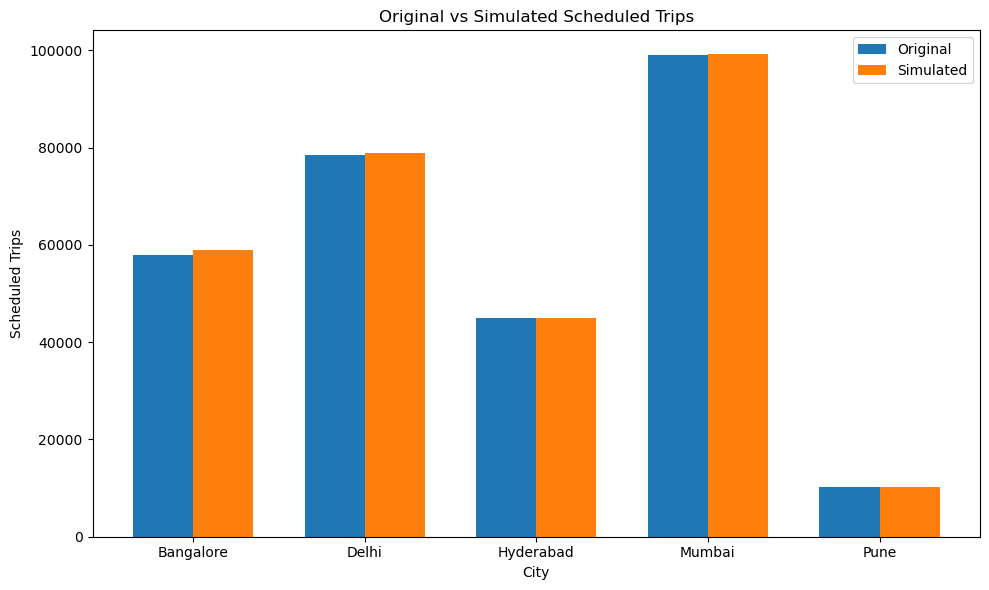

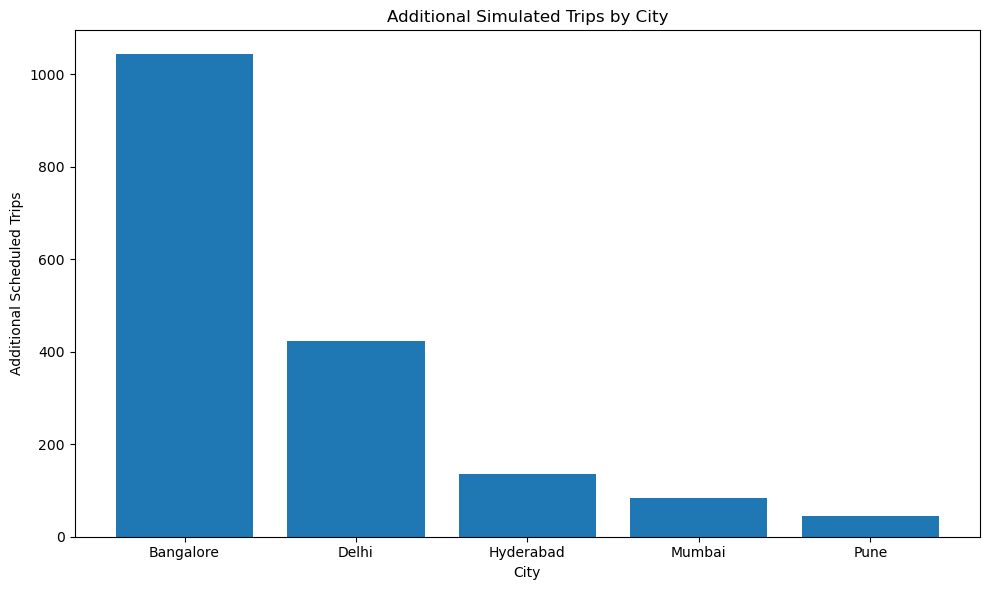

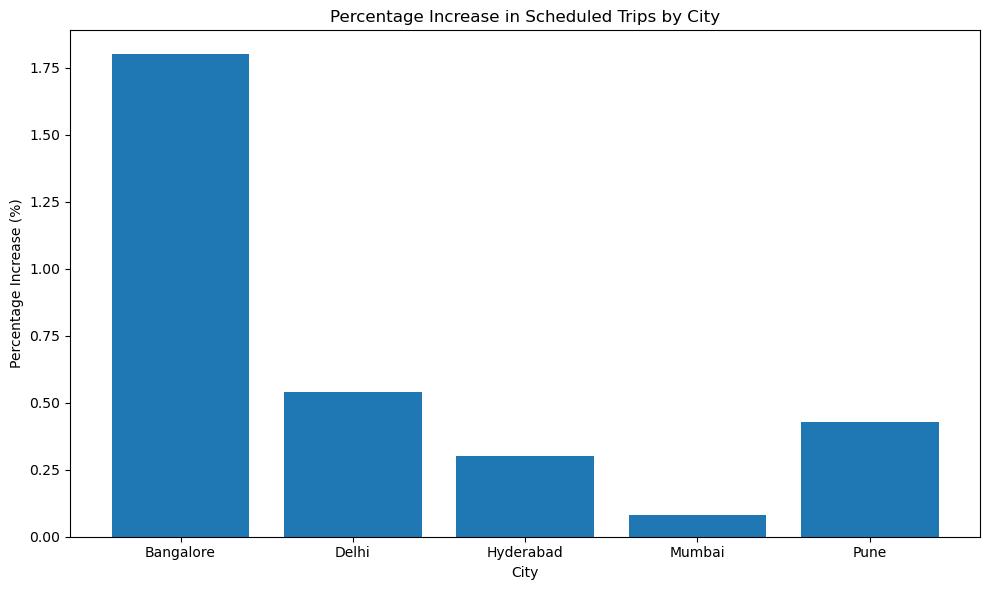

All three Module 6 charts saved in:
c:\Users\nagar\Downloads\routeranker-upload\data\processed\module6\visualizations


In [32]:
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = output_dir / "visualizations"
fig_dir.mkdir(parents=True, exist_ok=True)

# Chart 1: Original vs simulated scheduled trips
plt.figure(figsize=(10, 6))

x = range(len(city_comparison))
width = 0.35

plt.bar(
    [i - width / 2 for i in x],
    city_comparison["original_trips"],
    width,
    label="Original"
)

plt.bar(
    [i + width / 2 for i in x],
    city_comparison["simulated_trips"],
    width,
    label="Simulated"
)

plt.xticks(list(x), city_comparison["city"])
plt.xlabel("City")
plt.ylabel("Scheduled Trips")
plt.title("Original vs Simulated Scheduled Trips")
plt.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "module6_original_vs_simulated.png",
    dpi=300
)
plt.show()


# Chart 2: Additional simulated trips
plt.figure(figsize=(10, 6))

plt.bar(
    city_comparison["city"],
    city_comparison["additional_trips"]
)

plt.xlabel("City")
plt.ylabel("Additional Scheduled Trips")
plt.title("Additional Simulated Trips by City")
plt.tight_layout()

plt.savefig(
    fig_dir / "module6_additional_trips_by_city.png",
    dpi=300
)
plt.show()


# Chart 3: Percentage increase
plt.figure(figsize=(10, 6))

plt.bar(
    city_comparison["city"],
    city_comparison["percentage_increase"]
)

plt.xlabel("City")
plt.ylabel("Percentage Increase (%)")
plt.title("Percentage Increase in Scheduled Trips by City")
plt.tight_layout()

plt.savefig(
    fig_dir / "module6_percentage_increase_by_city.png",
    dpi=300
)
plt.show()

print("All three Module 6 charts saved in:")
print(fig_dir)

In [33]:
# Select useful route-level review information
candidate_report = optimization_df[
    [
        "city",
        "route_id",
        "route_long_name",
        "route_short_name",
        "trip_count",
        "service_count",
        "distinct_stop_count",
        "average_stops_per_trip",
        "kmeans_cluster",
        "dbscan_cluster",
        "dbscan_assignment_ambiguous",
        "low_trip_count_candidate",
        "high_trip_count_candidate",
        "dbscan_noise_candidate"
    ]
].copy()

# Keep routes with at least one review indicator
candidate_report = candidate_report[
    candidate_report[
        [
            "low_trip_count_candidate",
            "high_trip_count_candidate",
            "dbscan_noise_candidate",
            "dbscan_assignment_ambiguous"
        ]
    ].any(axis=1)
].copy()

# Sort to make the report easier to review
candidate_report = candidate_report.sort_values(
    ["city", "low_trip_count_candidate", "dbscan_noise_candidate"],
    ascending=[True, False, False]
)

# Save report
candidate_report.to_csv(
    output_dir / "module6_route_optimization_candidates.csv",
    index=False
)

print("Total candidate records:", len(candidate_report))

print("\nCandidates by city:")
print(candidate_report.groupby("city").size())

print("\nReview indicator totals:")
print(
    candidate_report[
        [
            "low_trip_count_candidate",
            "high_trip_count_candidate",
            "dbscan_noise_candidate",
            "dbscan_assignment_ambiguous"
        ]
    ].sum()
)

print("\nSample candidate records:")
display(candidate_report.head(10))

print("\nCandidate report saved successfully.")

Total candidate records: 2680

Candidates by city:
city
Bangalore    1485
Delhi         723
Hyderabad     261
Mumbai        133
Pune           78
dtype: int64

Review indicator totals:
low_trip_count_candidate       1711
high_trip_count_candidate       939
dbscan_noise_candidate          126
dbscan_assignment_ambiguous       2
dtype: int64

Sample candidate records:


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
8,Bangalore,7674,8th Mile Dasarahalli ⇔ Depot-31 Gate,8THM-D31G,1.0,1.0,18.0,18.0,1,0,False,True,False,False
15,Bangalore,8541,AECS Layout Singasandra ⇔ Koramangala Bus Station,347-K KRMBS-AECS,1.0,1.0,16.0,16.0,1,0,False,True,False,False
18,Bangalore,7653,AGS Layout Cross ⇔ Kempegowda Bus Station,45-G AGSLC-KBS,1.0,1.0,15.0,15.0,1,0,False,True,False,False
21,Bangalore,7549,ARMY PUBLIC SCHOOL (Parachute Regiment) ⇔ Shiv...,SBS-ARMYPR,1.0,1.0,11.0,11.0,1,0,False,True,False,False
25,Bangalore,3908,Abbigere ⇔ Kempegowda Bus Station,271-A KBS-VSD-ABG,1.0,1.0,27.0,27.0,1,0,False,True,False,False
27,Bangalore,4759,Abbigere ⇔ Peenya 2nd stage,270-D PSS-ABG,1.0,1.0,19.0,19.0,1,0,False,True,False,False
28,Bangalore,4798,Abbigere ⇔ Peenya 2nd stage,273-B PSS-ABG,1.0,1.0,16.0,16.0,1,0,False,True,False,False
29,Bangalore,3907,Abbigere ⇔ Peenya 2nd stage,401-AK ABG-PSS,1.0,1.0,19.0,19.0,1,0,False,True,False,False
32,Bangalore,7616,Acharya Institute of Technology ⇔ KR Market,V-250SB,1.0,1.0,33.0,33.0,1,0,False,True,False,False
34,Bangalore,9623,Addiganahalli ⇔ Depot-46 Gate,D46G-ADGH,1.0,1.0,3.0,3.0,1,0,False,True,False,False



Candidate report saved successfully.


In [34]:
print("Total candidate records:", len(candidate_report))

print("\nCities included:")
print(
    candidate_report["city"]
    .value_counts()
    .sort_index()
)

print("\nFirst 5 records:")
display(candidate_report.head(5))

print("\nLast 5 records:")
display(candidate_report.tail(5))

print("\nAll cities present:")
print(sorted(candidate_report["city"].dropna().unique()))

Total candidate records: 2680

Cities included:
city
Bangalore    1485
Delhi         723
Hyderabad     261
Mumbai        133
Pune           78
Name: count, dtype: int64

First 5 records:


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
8,Bangalore,7674,8th Mile Dasarahalli ⇔ Depot-31 Gate,8THM-D31G,1.0,1.0,18.0,18.0,1,0,False,True,False,False
15,Bangalore,8541,AECS Layout Singasandra ⇔ Koramangala Bus Station,347-K KRMBS-AECS,1.0,1.0,16.0,16.0,1,0,False,True,False,False
18,Bangalore,7653,AGS Layout Cross ⇔ Kempegowda Bus Station,45-G AGSLC-KBS,1.0,1.0,15.0,15.0,1,0,False,True,False,False
21,Bangalore,7549,ARMY PUBLIC SCHOOL (Parachute Regiment) ⇔ Shiv...,SBS-ARMYPR,1.0,1.0,11.0,11.0,1,0,False,True,False,False
25,Bangalore,3908,Abbigere ⇔ Kempegowda Bus Station,271-A KBS-VSD-ABG,1.0,1.0,27.0,27.0,1,0,False,True,False,False



Last 5 records:


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
9280,Pune,64,Nda 10 No. Gate ⇆ Bhekrai Nagar,64,86.0,1.0,111.0,61.000000,0,0,False,False,True,False
9309,Pune,98,Kesnand Phata Wagholi ⇆ Ganpati Matha,98,93.0,1.0,93.0,55.924731,0,0,False,False,True,False
9310,Pune,99,Kekan Gas ⇆ Kothrud Depot,99,88.0,1.0,72.0,40.136364,0,0,False,False,True,False
9315,Pune,H8,Fursungi ⇆ Hadapsar Gadital,H8,110.0,1.0,28.0,16.000000,1,0,False,False,True,False
9316,Pune,H9,Manjari Budruk ⇆ Hadapsar Gadital Solapur Road,H9,103.0,1.0,28.0,15.000000,1,0,False,False,True,False



All cities present:
['Bangalore', 'Delhi', 'Hyderabad', 'Mumbai', 'Pune']


In [35]:
cities = ["Bangalore", "Delhi", "Hyderabad", "Mumbai", "Pune"]

for city in cities:
    city_data = candidate_report[
        candidate_report["city"] == city
    ]

    print(f"\n{'=' * 60}")
    print(f"{city.upper()} — {len(city_data)} CANDIDATE ROUTES")
    print("=" * 60)

    display(city_data.head(10))

# Verify all cities are represented
print("\nFINAL CITY SUMMARY:")
print(candidate_report.groupby("city").size())

# Save the complete report again
candidate_report.to_csv(
    output_dir / "module6_route_optimization_candidates.csv",
    index=False
)

print("\nComplete five-city candidate report saved successfully.")


BANGALORE — 1485 CANDIDATE ROUTES


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
8,Bangalore,7674,8th Mile Dasarahalli ⇔ Depot-31 Gate,8THM-D31G,1.0,1.0,18.0,18.0,1,0,False,True,False,False
15,Bangalore,8541,AECS Layout Singasandra ⇔ Koramangala Bus Station,347-K KRMBS-AECS,1.0,1.0,16.0,16.0,1,0,False,True,False,False
18,Bangalore,7653,AGS Layout Cross ⇔ Kempegowda Bus Station,45-G AGSLC-KBS,1.0,1.0,15.0,15.0,1,0,False,True,False,False
21,Bangalore,7549,ARMY PUBLIC SCHOOL (Parachute Regiment) ⇔ Shiv...,SBS-ARMYPR,1.0,1.0,11.0,11.0,1,0,False,True,False,False
25,Bangalore,3908,Abbigere ⇔ Kempegowda Bus Station,271-A KBS-VSD-ABG,1.0,1.0,27.0,27.0,1,0,False,True,False,False
27,Bangalore,4759,Abbigere ⇔ Peenya 2nd stage,270-D PSS-ABG,1.0,1.0,19.0,19.0,1,0,False,True,False,False
28,Bangalore,4798,Abbigere ⇔ Peenya 2nd stage,273-B PSS-ABG,1.0,1.0,16.0,16.0,1,0,False,True,False,False
29,Bangalore,3907,Abbigere ⇔ Peenya 2nd stage,401-AK ABG-PSS,1.0,1.0,19.0,19.0,1,0,False,True,False,False
32,Bangalore,7616,Acharya Institute of Technology ⇔ KR Market,V-250SB,1.0,1.0,33.0,33.0,1,0,False,True,False,False
34,Bangalore,9623,Addiganahalli ⇔ Depot-46 Gate,D46G-ADGH,1.0,1.0,3.0,3.0,1,0,False,True,False,False



DELHI — 723 CANDIDATE ROUTES


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
4418,Delhi,2,819STLDOWN,NaN,4.0,1.0,4.0,4.0,1,0,False,True,False,False
4423,Delhi,7,829STLUP,NaN,3.0,1.0,7.0,7.0,1,0,False,True,False,False
4438,Delhi,22,790BDOWN,NaN,4.0,1.0,48.0,48.0,0,0,False,True,False,False
4461,Delhi,45,701STLDOWN,NaN,2.0,1.0,22.0,22.0,1,0,False,True,False,False
4466,Delhi,50,873STLUP,NaN,4.0,1.0,9.0,9.0,1,0,False,True,False,False
4512,Delhi,96,770ALTDUP,NaN,1.0,1.0,58.0,58.0,0,0,False,True,False,False
4515,Delhi,99,206UP,NaN,2.0,1.0,36.0,36.0,1,0,False,True,False,False
4538,Delhi,122,114EXTUP,NaN,4.0,1.0,48.0,48.0,0,0,False,True,False,False
4539,Delhi,123,107UP,NaN,4.0,1.0,61.0,61.0,0,0,False,True,False,False
4542,Delhi,126,828AUP,NaN,2.0,1.0,26.0,26.0,1,0,False,True,False,False



HYDERABAD — 261 CANDIDATE ROUTES


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
7383,Hyderabad,100B,100B,NaN,1.0,1.0,23.0,23.0,1,0,False,True,False,False
7385,Hyderabad,100G/L,100G/L,NaN,1.0,1.0,5.0,5.0,1,0,False,True,False,False
7386,Hyderabad,100G/S,100G/S,NaN,1.0,1.0,18.0,18.0,1,0,False,True,False,False
7397,Hyderabad,102/277,102/277,NaN,1.0,1.0,13.0,13.0,1,0,False,True,False,False
7400,Hyderabad,102K,102K,NaN,1.0,1.0,14.0,14.0,1,0,False,True,False,False
7404,Hyderabad,104A/218,104A/218,NaN,1.0,1.0,59.0,59.0,0,0,False,True,False,False
7407,Hyderabad,104R/127K,104R/127K,NaN,1.0,1.0,43.0,43.0,0,0,False,True,False,False
7413,Hyderabad,107M,107M,NaN,1.0,1.0,36.0,36.0,1,0,False,True,False,False
7414,Hyderabad,107R,107R,NaN,1.0,1.0,22.0,22.0,1,0,False,True,False,False
7415,Hyderabad,107R/300A,107R/300A,NaN,1.0,1.0,52.0,52.0,0,0,False,True,False,False



MUMBAI — 133 CANDIDATE ROUTES


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
9003,Mumbai,308-2,Shirsad Phata ⇆ Mandvi Forest Check Post,308,11.0,1.0,116.0,116.0,0,-1,False,True,False,True
8411,Mumbai,2-1,Kalyan Station To Kalyan Station Via Birla Col...,2,1.0,1.0,26.0,26.0,1,0,False,True,False,False
8412,Mumbai,4-7,Niwasi To Depot (Up) ⇆ Niwasi To Depot (Up),4,4.0,1.0,22.0,22.0,1,0,False,True,False,False
8413,Mumbai,7-1,Kalyan Station To Mohana Colony (Up) ⇆ Kalyan ...,7,3.0,1.0,18.0,18.0,1,0,False,True,False,False
8414,Mumbai,7-2,Mohana Colony To Kalyan Station (Down) ⇆ Mohan...,7,3.0,1.0,18.0,18.0,1,0,False,True,False,False
8415,Mumbai,20-1,Kalyan Station To Panvel (Up) ⇆ Kalyan Station...,20,3.0,1.0,60.0,60.0,0,0,False,True,False,False
8416,Mumbai,20-2,Panvel To Kalyan Station (Down) ⇆ Panvel To Ka...,20,4.0,1.0,59.0,59.0,0,0,False,True,False,False
8417,Mumbai,34-1,Kalyan ⇆ Mankoli,34,1.0,1.0,22.0,22.0,1,0,False,True,False,False
8418,Mumbai,34-2,Mankoli ⇆ Kalyan,34,1.0,1.0,22.0,22.0,1,0,False,True,False,False
8419,Mumbai,45-1,Kalyan Station-Malangad (Up) ⇆ Kalyan Station-...,45,1.0,1.0,26.0,26.0,1,0,False,True,False,False



PUNE — 78 CANDIDATE ROUTES


,city,route_id,route_long_name,route_short_name,trip_count,service_count,distinct_stop_count,average_stops_per_trip,kmeans_cluster,dbscan_cluster,dbscan_assignment_ambiguous,low_trip_count_candidate,high_trip_count_candidate,dbscan_noise_candidate
9125,Pune,212,Morgaon St Stand ⇆ Hadapsar Gadital,212,3.0,1.0,188.0,112.000000,0,-1,False,True,False,True
9137,Pune,231,Shilim Gaon ⇆ Marketyard Depot,231,4.0,1.0,212.0,117.500000,0,-1,False,True,False,True
9028,Pune,111M,Ma Na Pa Congress Bhavan ⇆ Bhekrai Nagar,111M,4.0,1.0,74.0,37.000000,0,0,False,True,False,False
9035,Pune,119A,Charholigaon ⇆ Ma Na Pa Daphale Garage,119A,5.0,1.0,85.0,45.200000,0,0,False,True,False,False
9037,Pune,11A,Kasarwadi Railway Station ⇆ Marketyard Depot,11A,4.0,1.0,92.0,48.000000,0,0,False,True,False,False
9048,Pune,131,Golegaon Gram Panchayat ⇆ Ma Na Pa Dengle Pul ...,131,5.0,1.0,100.0,51.200000,0,0,False,True,False,False
9052,Pune,135,Ranjangaon Sandas ⇆ Ma Na Pa Shramik Bhavan,135,3.0,1.0,165.0,105.666667,0,0,False,True,False,False
9058,Pune,140A,Pune Station Jayprakash Stand ⇆ Katraj Kondhwa...,140A,4.0,1.0,60.0,31.000000,0,0,False,True,False,False
9067,Pune,147,Nhavi Sandas ⇆ Ma Na Pa Shramik Bhavan,147,3.0,1.0,131.0,70.666667,0,0,False,True,False,False
9084,Pune,162,Pabal Gaon ⇆ Ma Na Pa Shramik Bhavan,162,5.0,1.0,161.0,90.400000,0,0,False,True,False,False



FINAL CITY SUMMARY:
city
Bangalore    1485
Delhi         723
Hyderabad     261
Mumbai        133
Pune           78
dtype: int64

Complete five-city candidate report saved successfully.


In [36]:
from pathlib import Path

# Create reports folder
reports_dir = root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Calculate report statistics
total_routes = len(optimization_df)
total_hourly_records = len(simulated_hourly_df)

kmeans_summary = (
    optimization_df["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

dbscan_summary = (
    optimization_df["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

candidate_city_summary = (
    candidate_report.groupby("city").size()
)

original_total = int(simulated_hourly_df["original_trip_count"].sum())
simulated_total = int(simulated_hourly_df["simulated_trip_count"].sum())
additional_total = simulated_total - original_total

percentage_increase = (
    additional_total / original_total * 100
)

# Build city comparison table
city_table = city_comparison.to_markdown(index=False)

# Build clustering summaries
kmeans_table = kmeans_summary.rename("route_count").to_frame().to_markdown()
dbscan_table = dbscan_summary.rename("route_count").to_frame().to_markdown()

# Build candidate summary
candidate_table = candidate_city_summary.rename(
    "candidate_records"
).to_frame().to_markdown()

report = f"""
# RouteRanker — Module 6
## Model Inference and Route Optimization

### 1. Objective

Module 6 applies the trained Module 5 clustering models to the available
route feature dataset, identifies routes for further investigation, and
evaluates an illustrative schedule-based optimization scenario.

### 2. Data and model inference

- Eligible route records: **{total_routes}**
- Hourly schedule records: **{total_hourly_records}**
- Cities: Bangalore, Delhi, Hyderabad, Mumbai and Pune.
- KMeans model: loaded from the saved Module 5 model.
- DBSCAN model: loaded from the saved Module 5 model.
- KMeans inference: nearest-centroid prediction using the original
  three Module 5 features.
- DBSCAN inference: approximate assignment using saved core samples
  and the model's epsilon neighborhood.

The inference dataset contains the same records used during Module 5
training. Therefore, agreement with the original cluster assignments
validates reproduction of previous assignments, not generalization to
independent unseen data.

### 3. KMeans cluster distribution

{ kmeans_table }

Cluster identifiers are descriptive group labels. They are not route
quality rankings.

### 4. DBSCAN neighborhood assignment distribution

{ dbscan_table }

Noise points are routes that were not assigned to a DBSCAN core-point
neighborhood. Ambiguous assignments are flagged for further review.

### 5. Route optimization candidates

The candidate analysis uses city-specific scheduled trip-count
percentiles and clustering indicators.

Total candidate records: **{len(candidate_report)}**

{candidate_table}

These records are candidates for manual investigation. Low or high
scheduled trip counts and DBSCAN noise do not independently prove
that a route is inefficient.

### 6. Schedule simulation

An illustrative scenario increased scheduled trips by 10 percent for
routes flagged as low scheduled-trip-count candidates.

- Original scheduled trips: **{original_total:,}**
- Simulated scheduled trips: **{simulated_total:,}**
- Additional simulated trips: **{additional_total:,}**
- Percentage increase: **{percentage_increase:.2f}%**
- Routes receiving simulated increases: **{int(city_comparison['route_count'].sum() if False else optimization_df.loc[optimization_df['low_trip_count_candidate'], ['city', 'route_id']].drop_duplicates().shape[0]):,}**

This scenario is an arithmetic simulation, not an operational
recommendation. Passenger demand and vehicle capacity were not
available to justify actual service increases.

### 7. City-wise comparison

{city_table}

### 8. Visualizations

The following charts were generated:

- module6_original_vs_simulated.png
- module6_additional_trips_by_city.png
- module6_percentage_increase_by_city.png
- module6_kmeans_city_distribution.png
- module6_dbscan_noise_percentage.png
- module6_kmeans_cluster_profiles.png

### 9. Limitations

1. Independent unseen route data was not available for this inference run.
2. Passenger demand and vehicle capacity data were unavailable.
3. Scheduled trips represent service supply, not passenger demand.
4. Route merging and splitting were not simulated because sufficient
   route-overlap, connectivity and operational validation was not
   established.
5. The simulation does not establish that additional trips are needed.
6. Estimated distance and geographic coverage were not included in
   the simulation comparison.
7. The 341 route-profile records with missing model features were
   excluded from model inference.

### 10. Conclusion

Module 6 successfully loaded the saved Module 5 models, reproduced
cluster assignments for 9,338 eligible route records, generated
route-review candidates, and produced a separate simulated hourly
schedule.

The scenario increased scheduled trips by {percentage_increase:.2f}%.
All findings should be treated as analytical evidence for further
investigation rather than confirmed operational improvements.
"""

report_path = reports_dir / "MODULE6_INFERENCE_AND_ROUTE_OPTIMIZATION_REPORT.md"
report_path.write_text(report, encoding="utf-8")

print("Module 6 report created successfully:")
print(report_path)
print("\nReport size:", report_path.stat().st_size, "bytes")

Module 6 report created successfully:
c:\Users\nagar\Downloads\routeranker-upload\reports\MODULE6_INFERENCE_AND_ROUTE_OPTIMIZATION_REPORT.md

Report size: 5116 bytes


In [37]:
assumptions_text = """
# RouteRanker — Module 6
## Assumptions and Limitations

### 1. Model inference assumptions

- The saved KMeans and DBSCAN models from Module 5 are reused.
- The same three model features are used:
  trip_count, distinct_stop_count, average_stops_per_trip.
- The Module 4 feature representation is preserved.
- No new scaler is fitted for inference.
- KMeans assigns records using the saved cluster centroids.
- DBSCAN does not provide a native predict method. Approximate
  assignment uses saved core samples and the original epsilon radius.

### 2. Data alignment assumptions

- The eligible route-profile dataset contains 9,338 records.
- The 341 records with missing model features are excluded.
- The eligible route records were validated against the Module 4
  feature dataset.
- Numeric standardized feature values matched within numerical
  floating-point tolerance.
- City and route identifiers are used to associate predictions
  with route-level and hourly schedule records.

### 3. Candidate identification assumptions

- Low scheduled trip-count candidates are identified using the
  city-specific 10th percentile.
- High scheduled trip-count candidates are identified using the
  city-specific 90th percentile.
- DBSCAN noise and ambiguous assignments are additional review flags.
- These indicators do not prove route inefficiency.

### 4. Simulation assumptions

- An illustrative 10 percent increase is applied to low-trip-count
  candidate routes.
- Additional whole trips are distributed proportionally across
  existing hourly schedule records for each route.
- The original hourly dataset is preserved.
- The simulation is stored separately from the original schedule.
- The scenario is not an operational recommendation.

### 5. Data limitations

- Independent unseen route data was not available for this run.
- Passenger counts and passenger demand were not available.
- Vehicle capacity and occupancy data were not available.
- Actual operating costs and vehicle availability were not available.
- Reliable route-overlap and connectivity validation was not
  established for merging or splitting routes.
- Distance and geographic coverage were not included in the
  simulation comparison.
- Schedule-based trip counts represent planned service, not
  actual passenger usage.

### 6. Interpretation limitations

- KMeans cluster numbers are labels, not performance rankings.
- DBSCAN noise points are unusual in feature space, not necessarily
  bad or inefficient routes.
- High scheduled trip counts do not automatically mean overcrowding.
- Low scheduled trip counts do not automatically mean insufficient
  service.
- The simulated increase does not demonstrate improved passenger
  outcomes.

### 7. Future improvements

- Validate predictions using independent unseen GTFS data.
- Integrate passenger demand and vehicle capacity information.
- Include route geometry, route distance and stop coverage.
- Evaluate service changes using operational constraints.
- Validate route merging and splitting using stop overlap,
  connectivity and passenger journey information.
- Compare simulated schedules against observed operational outcomes.
"""

assumptions_path = (
    reports_dir / "MODULE6_ASSUMPTIONS_AND_LIMITATIONS.md"
)

assumptions_path.write_text(
    assumptions_text.strip(),
    encoding="utf-8"
)

print("Assumptions document created:")
print(assumptions_path)

print("\nFile size:", assumptions_path.stat().st_size, "bytes")

Assumptions document created:
c:\Users\nagar\Downloads\routeranker-upload\reports\MODULE6_ASSUMPTIONS_AND_LIMITATIONS.md

File size: 3244 bytes
